In [ ]:
# STEP 2 (downloading data)
!kaggle datasets download -d tongpython/cat-and-dog

Dataset URL: https://www.kaggle.com/datasets/tongpython/cat-and-dog
License(s): CC0-1.0
100% 218M/218M [00:02<00:00, 108MB/s]



In [ ]:
# STEP 3 (unzip data)
import zipfile
zip_ref=zipfile.ZipFile('cat-and-dog.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
# STEP 4 (Install Keras Tuner)
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [ ]:
import tensorflow as tf
import keras
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, BatchNormalization,Dense,Dropout,MaxPooling2D,Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from matplotlib import pyplot as plt

In [ ]:
#generator :
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/training_set/training_set",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "training",
    seed = 42
)

val_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/training_set/training_set",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "validation",
    seed = 42
)

test_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/test_set/test_set",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),

)

train_ds = train_ds.take(500)
val_ds = val_ds.take(100)
test_ds = test_ds.take(100)

Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Found 8005 files belonging to 2 classes.
Using 1601 files for validation.
Found 2023 files belonging to 2 classes.


In [ ]:
#normalization:
def process(image, label):
  image = tf.cast(image/255., tf.float32)
  return image, label
train_ds = train_ds.map(process)
val_ds = val_ds.map(process)
test_ds = test_ds.map(process)

In [ ]:
def build_model(hp):
  model = Sequential()
  model.add(Conv2D(filters= hp.Choice("filter1",values = [32,64,128]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu",
                   input_shape =(256,256,3)))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  #hidden layer1:
  model.add(Conv2D(filters=hp.Choice("filter2", values = [64, 128,256]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

   #hidden layer2:
  model.add(Conv2D(filters=hp.Choice("filter3", values = [128,256,512]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  #hidden layer3:
  model.add(Conv2D(filters=hp.Choice("filter4", values = [128,256,512]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  model.add(Flatten())

  model.add(Dense(units=hp.Choice("unit1", values = [256,512]),
                                  activation = "relu",
                                  ))

  model.add(Dropout(rate=hp.Choice("dropout", values =[0.1,0.2,0.3,0.4,0.5])))

  model.add(Dense(1,activation = "sigmoid"))

  model.compile(optimizer = Adam(learning_rate = hp.Choice("learning_rate",values = [0.001,0.0001])),
                                 loss = "binary_crossentropy",
                                 metrics = ["accuracy"])
  return model

In [ ]:
tuner = kt.Hyperband(
    build_model,
    objective = "val_accuracy",
    factor =3,
    max_epochs = 20,
    directory ="tuner_result"
)
tuner.search_space_summary()

Search space summary
Default search space size: 7
filter1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
filter2 (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
filter3 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
filter4 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
unit1 (Choice)
{'default': 256, 'conditions': [], 'values': [256, 512], 'ordered': True}
dropout (Choice)
{'default': 0.1, 'conditions': [], 'values': [0.1, 0.2, 0.3, 0.4, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0001], 'ordered': True}


In [ ]:
tuner.search(
    train_ds,
    epochs = 20,
    validation_data = val_ds,
    callbacks = EarlyStopping(monitor = "val_loss", patience = 3)
)

Trial 2 Complete [00h 00m 00s]

Best val_accuracy So Far: None
Total elapsed time: 00h 00m 01s

Search: Running Trial #3

Value             |Best Value So Far |Hyperparameter
32                |64                |filter1
128               |256               |filter2
256               |256               |filter3
512               |128               |filter4
512               |256               |unit1
0.4               |0.1               |dropout
0.001             |0.001             |learning_rate
3                 |3                 |tuner/epochs
0                 |0                 |tuner/initial_epoch
2                 |2                 |tuner/bracket
0                 |0                 |tuner/round



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/base_tuner.py", line 274, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/base_tuner.py", line 239, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/tuners/hyperband.py", line 427, in run_trial
    return super().run_trial(trial, *fit_args, **fit_kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/tuner.py", line 309, in run_trial
    self._configure_tensorboard_dir(callbacks, trial, execution)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/

RuntimeError: Number of consecutive failures exceeded the limit of 3.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/base_tuner.py", line 274, in _try_run_and_update_trial
    self._run_and_update_trial(trial, *fit_args, **fit_kwargs)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/base_tuner.py", line 239, in _run_and_update_trial
    results = self.run_trial(trial, *fit_args, **fit_kwargs)
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/tuners/hyperband.py", line 427, in run_trial
    return super().run_trial(trial, *fit_args, **fit_kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/keras_tuner/src/engine/tuner.py", line 309, in run_trial
    self._configure_tensorboard_dir(callbacks, trial, execution)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^

In [ ]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print('Best values found by Keras Tuner:')
print('=================================')
print('Block 1 filters :', best_hps.get('filter1'))
print('Block 2 filters :', best_hps.get('filter2'))
print('Block 3 filters :', best_hps.get('filter3'))
print('Block 4 filters :', best_hps.get('filter4'))
print('Dense units     :', best_hps.get('unit1'))
print('Dropout rate    :', best_hps.get('dropout'))
print('Learning rate   :', best_hps.get('learning_rate'))

Best values found by Keras Tuner:
Block 1 filters : 64
Block 2 filters : 256
Block 3 filters : 256
Block 4 filters : 128
Dense units     : 256
Dropout rate    : 0.1
Learning rate   : 0.001


In [ ]:
from keras_tuner.src.backend.keras import callbacks
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

final_early_stopping = EarlyStopping(monitor = "val_loss",
                                     mode = "min",
                                     patience = 5,
                                     restore_best_weights = True)
history = best_model.fit(train_ds,
                         validation_data = val_ds,
                         epochs = 50,
                         callbacks = [final_early_stopping])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 256)  │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128, 128, 256)  │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,426,561 (35.96 MB)

 Trainable params: 9,425,153 (35.95 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 139s 400ms/step - accuracy: 0.5973 - loss: 1.2800 - val_accuracy: 0.4903 - val_loss: 0.9887
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 55s 273ms/step - accuracy: 0.6635 - loss: 0.6120 - val_accuracy: 0.5871 - val_loss: 0.8142
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 53s 263ms/step - accuracy: 0.6972 - loss: 0.5728 - val_accuracy: 0.6677 - val_loss: 0.6140
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 54s 268ms/step - accuracy: 0.7467 - loss: 0.5154 - val_accuracy: 0.7108 - val_loss: 0.6096
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 53s 265ms/step - accuracy: 0.7904 - loss: 0.4434 - val_accuracy: 0.7208 - val_loss: 0.5854
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 55s 275ms/step - accuracy: 0.8084 - loss: 0.4103 - val_accuracy: 0.6552 - val_loss: 0.7971
Epoch 7/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 55s 275ms/step - accuracy: 0.8515 - loss: 0.3192 - val_accuracy: 0.7102 - val_loss: 0.7491
Epoch 8/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 53s 264ms/step - accuracy: 0.8626 - loss: 

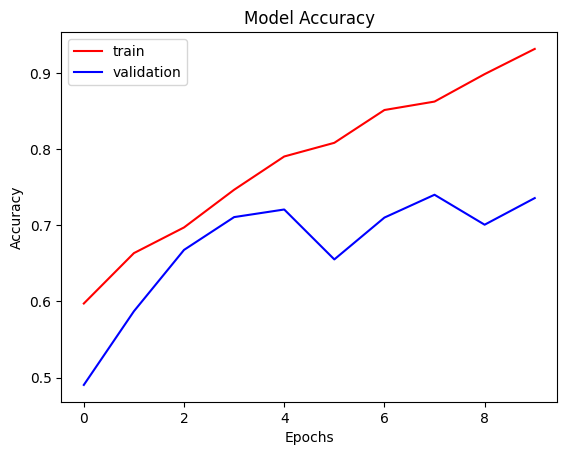

In [26]:
# STEP 13 - Plot Accuracy
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

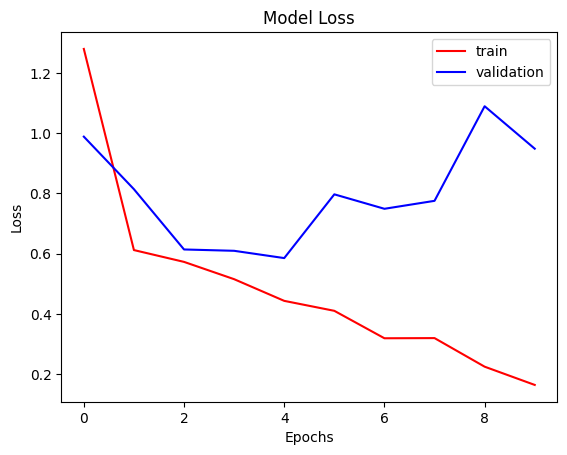

In [27]:
# STEP 14 - Plot Loss
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [28]:
test_accracy = best_model.evaluate(test_ds)
print(test_accracy)

64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 153ms/step - accuracy: 0.7261 - loss: 0.5966
[0.5965891480445862, 0.7261492609977722]


In [29]:
import cv2

In [30]:
test_img = cv2.imread("/content/dog.jpg")

In [31]:
test_img = cv2.resize(test_img,(256,256))

In [34]:
test_input = test_img.reshape(1,256,256,3)
test_input = test_input/255.0

In [37]:
prediction = best_model(test_input)
print(prediction)

tf.Tensor([[0.93083274]], shape=(1, 1), dtype=float32)
